# Data Exploration: Employment Position Records

This notebook explores the employment history data in the **assignment** folder before we design the coalescing algorithm.

Each row is one position (company, title, dates, location, description) as it appeared on a user's profile on a given date (`observed_ts`). The same user is observed several times, so the same real position can appear many times across snapshots, sometimes with slightly different details.

The goal here is only to understand the data: its size, structure, missing values, repetition, and how positions recur across snapshots. Nothing in this notebook cleans or changes the data.

**How to use it:** run the cells from top to bottom. Some sections reuse results from the section before them.

## 0. Setup

Mount Google Drive so the notebook can read the Parquet files.

In [18]:
from google.colab import drive
drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


Load the libraries and register all 32 Parquet files as one table called `positions`.

DuckDB reads the files directly from Drive, so we never load the whole dataset into memory. Every query below simply uses `FROM positions`.

In [19]:
%pip install -q duckdb

import duckdb
import pyarrow.parquet as pq
from pathlib import Path

data_dir = Path("/content/drive/MyDrive/assignment")
files = sorted(data_dir.glob("input__*.parquet"))
print("Parquet files found:", len(files))


assert files, "No Parquet files found"

con = duckdb.connect()
con.sql(f"CREATE VIEW positions AS SELECT * FROM read_parquet('{data_dir}/input__*.parquet')")

Parquet files found: 32


## 1. Dataset size

**Question:** How large is the dataset?

Counts the total rows, the number of distinct users, and the number of distinct observation dates.

In [20]:
con.sql("""
    SELECT
        COUNT(*)                    AS total_rows,
        COUNT(DISTINCT user_id)     AS total_users,
        COUNT(DISTINCT observed_ts) AS observation_dates
    FROM positions
""").df()

,total_rows,total_users,observation_dates
0,11480179,150000,2971


## 2. Schema consistency

**Question:** Do all 32 files have the same columns and data types?

Reads each file's schema (without reading the data). If the number of distinct schemas is **1**, every file has the same structure.

In [21]:
schemas = {str(pq.read_schema(f)) for f in files}

print("Distinct schemas:", len(schemas))
print(schemas.pop())

Distinct schemas: 1
observed_ts: date32[day]
user_id: int64
company_raw: string
company_website: string
title_raw: string
location_raw: string
description: string
startdate: date32[day]
enddate: date32[day]
order_in_profile: int32


## 3. Missing values

**Question**: Which fields have missing information, and how much?

Counts NULL values, empty strings, and whitespace-only strings as missing values in text columns. For date columns, only NULL values are counted. Shows the missing-value counts and their percentages of all rows.

In [22]:
missing = con.sql("""
    SELECT
        COUNT(*) FILTER (
            WHERE description IS NULL OR TRIM(description) = ''
        ) AS description,

        COUNT(*) FILTER (
            WHERE location_raw IS NULL OR TRIM(location_raw) = ''
        ) AS location_raw,

        COUNT(*) FILTER (
            WHERE company_website IS NULL OR TRIM(company_website) = ''
        ) AS company_website,

        COUNT(*) FILTER (
            WHERE enddate IS NULL
        ) AS enddate,

        COUNT(*) FILTER (
            WHERE startdate IS NULL
        ) AS startdate,

        COUNT(*) FILTER (
            WHERE title_raw IS NULL OR TRIM(title_raw) = ''
        ) AS title_raw,

        COUNT(*) FILTER (
            WHERE company_raw IS NULL OR TRIM(company_raw) = ''
        ) AS company_raw,

        COUNT(*) AS total_rows

    FROM positions
""").df().T

missing.columns = ["missing"]
missing["percent"] = (
    100 * missing["missing"] / missing.loc["total_rows", "missing"]
).round(2)

missing

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,missing,percent
description,7328619,63.84
location_raw,5253109,45.76
company_website,5008069,43.62
enddate,4482284,39.04
startdate,1709582,14.89
title_raw,107378,0.94
company_raw,44095,0.38
total_rows,11480179,100.00


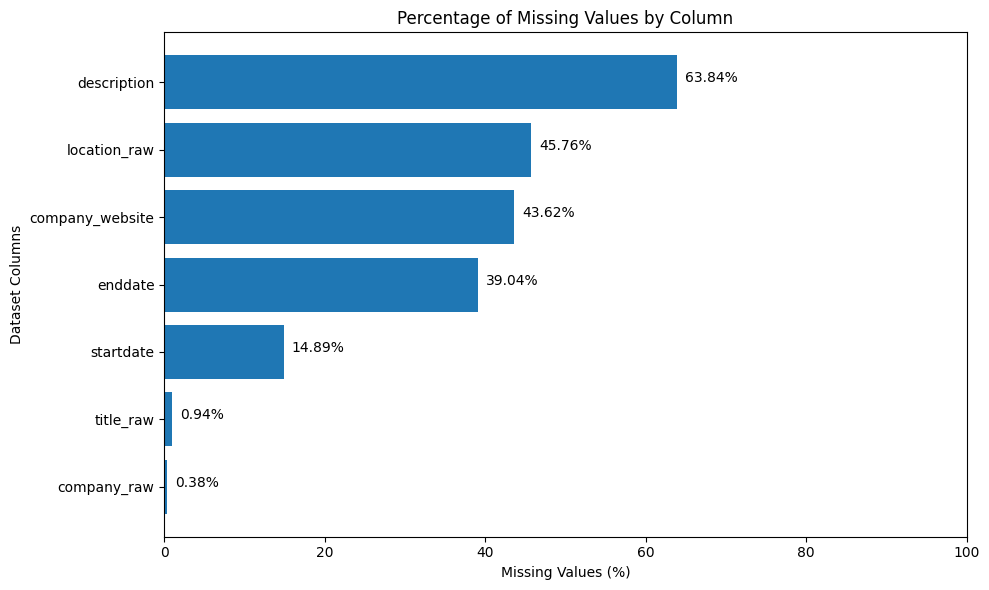

In [ ]:
import matplotlib.pyplot as plt

plot_data = missing.drop("total_rows").sort_values(
    by="percent",
    ascending=True
)

plt.figure(figsize=(10, 6))

plt.barh(
    plot_data.index,
    plot_data["percent"]
)

plt.xlabel("Missing Values (%)")
plt.ylabel("Dataset Columns")
plt.title("Percentage of Missing Values by Column")

plt.xlim(0, 100)

for index, value in enumerate(plot_data["percent"]):
    plt.text(value + 1, index, f"{value:.2f}%")

plt.tight_layout()
plt.show()

## 4. Exact repeated records

**Question:** Within the same snapshot, are there rows with identical content?

Groups rows by every column except `order_in_profile` (which only records the position's place in the list) and keeps the groups that appear more than once. These are repeated content, not necessarily errors.

In [23]:
repeated = con.sql("""
    SELECT * EXCLUDE (order_in_profile), COUNT(*) AS record_count
    FROM positions
    GROUP BY ALL
    HAVING COUNT(*) > 1
""").df()

print("Repeated groups:        ", len(repeated))
print("Rows in repeated groups:", repeated["record_count"].sum())
print("Extra occurrences:      ", (repeated["record_count"] - 1).sum())

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Repeated groups:         121556
Rows in repeated groups: 324762
Extra occurrences:       203206


## 5. Repetition distribution

**Question:** How many times does the same content appear?

Uses the result of section 4, so no new scan of the data is needed. Shows how many groups appear 2 times, 3 times, and so on.

In [24]:
repeated["record_count"].value_counts().sort_index()

,count
record_count,
2,43311
3,76814
4,829
5,91
6,320
7,19
8,123
9,16
10,2


## 6. Observation sizes

**Question:** How many positions does a user have in each snapshot?

Counts rows per (user, observation date) pair and summarises them: average, median, minimum and maximum.

In [25]:
snapshot_sizes = con.sql("""
    SELECT user_id, observed_ts, COUNT(*) AS rows_in_snapshot
    FROM positions
    GROUP BY user_id, observed_ts
""").df()

snapshot_sizes["rows_in_snapshot"].describe()

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,rows_in_snapshot
count,3.941416e+06
mean,2.912704e+00
std,3.053513e+00
min,1.000000e+00
25%,1.000000e+00
50%,1.000000e+00
75%,4.000000e+00
max,3.700000e+02


## 7. Observation-size distribution

**Question:** How many snapshots are small, and how many are large?

Uses the result of section 6 and groups snapshots into size bands (1 row, 2-5 rows, 6-10, and so on).

In [26]:
sizes = snapshot_sizes["rows_in_snapshot"]

distribution = {
    "1": (sizes == 1).sum(),
    "2-5": sizes.between(2, 5).sum(),
    "6-10": sizes.between(6, 10).sum(),
    "11-20": sizes.between(11, 20).sum(),
    "21-50": sizes.between(21, 50).sum(),
    "50+": (sizes > 50).sum(),
}

distribution

{'1': np.int64(2063488),
 '2-5': np.int64(1239410),
 '6-10': np.int64(525015),
 '11-20': np.int64(107083),
 '21-50': np.int64(6231),
 '50+': np.int64(189)}

## 8. Recurring company-title combinations

**Question:** Does the same user have the same company and title across different snapshots?

Finds (user, company, title) combinations that appear in more than one snapshot, and counts how many different start and end dates each one has. Rows with a missing or blank company or title are skipped.

In [27]:
recurring = con.sql("""
    SELECT
        user_id,
        company_raw,
        title_raw,
        COUNT(DISTINCT observed_ts) AS snapshots,
        COUNT(*)                    AS total_records,
        COUNT(DISTINCT startdate)   AS distinct_start_dates,
        COUNT(DISTINCT enddate)     AS distinct_end_dates
    FROM positions
    WHERE TRIM(company_raw) <> '' AND TRIM(title_raw) <> ''
    GROUP BY user_id, company_raw, title_raw
    HAVING COUNT(DISTINCT observed_ts) > 1
""").df()

recurring.describe()

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,user_id,snapshots,total_records,distinct_start_dates,distinct_end_dates
count,4.935620e+05,493562.000000,493562.000000,493562.000000,493562.000000
mean,8.063930e+08,22.126021,22.642691,0.893333,0.638420
std,7.444066e+08,18.452378,18.946147,0.422062,0.550787
min,1.009545e+06,2.000000,2.000000,0.000000,0.000000
25%,2.605688e+08,6.000000,6.000000,1.000000,0.000000
50%,5.382923e+08,17.000000,18.000000,1.000000,1.000000
75%,9.851081e+08,35.000000,35.000000,1.000000,1.000000
max,2.402366e+09,187.000000,419.000000,14.000000,14.000000


## 9. Ambiguous company-title combinations


**Question:** Can the same user have the same company and title with more than one start date?

Uses the result of section 8. These cases matter because they show that company and title alone are not always enough to tell positions apart. For example, someone may return to the same role later, or the start date may have been edited.

In [28]:
ambiguous = recurring[recurring["distinct_start_dates"] > 1]

print("Ambiguous combinations:", len(ambiguous))
ambiguous.head(20)

Ambiguous combinations: 16633


,user_id,company_raw,title_raw,snapshots,total_records,distinct_start_dates,distinct_end_dates
30,337913553,Schachner Associates,Clinical Psychologist,46,46,2,1
35,210893443,Cooabriel - Cooperativa Agrária dos Cafeiculto...,Gerente de negócios,20,20,2,1
70,661257554,Partij voor de Dieren,Fractievoorzitter Partij voor de Dieren Gouda,26,26,2,0
85,35956824,Bradford White,Human Resources Manager,85,85,2,1
86,35956824,Bradford White Corporation,HR Safety Manager,68,68,2,1
93,474307396,Mako Global,Head of Application Support,52,52,2,1
124,317935190,Revixi World Marketing Inc,Information Technology Consultant,55,55,2,1
190,101544465,HealthIMPACT Live,Founder & CEO,54,55,2,0
192,101544465,Informa,"Director, Healthcare Events, IIRUSA",58,58,2,1
204,281676832,PPD,Associate Director,62,152,3,3


## 10. Inspect one user's history

**Question:** What does a real employment history look like across snapshots?

Shows every row for one user, ordered by observation date and position in the profile. Change `user_id` to look at someone else.

In [29]:
user_id = 270934170

history = con.execute(
    "SELECT * FROM positions WHERE user_id = ? ORDER BY observed_ts, order_in_profile",
    [user_id],
).df()

print(history.to_string(index=False))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

observed_ts   user_id                   company_raw                            company_website    title_raw                                 location_raw                                                                                                                                                                                                                                                                                                                                                                                                                         description  startdate    enddate  order_in_profile
 2019-11-29 270934170                     ASBL PARI                                       None   Animatrice                     Region de Liege, Belgium                                                                                                                                                                                                                                           